# Exploratory data analysis: bona fide vs screen attacks

What separates the two classes, how strongly, and which of those differences are **shortcuts** (artefacts of how this dataset was collected) rather than **cues** (properties of a screen recapture that should transfer to unseen attacks)?

Sections:
1. Dataset composition
2. File metadata: per-class distributions and separability
3. Shortcut demonstration: logistic regression on metadata alone
4. Face detection and crop geometry
5. Pixel and spectral statistics on the face crops (what a model sees)
6. Paired analysis: each attack against its own bona fide twin
7. What survives cropping: logistic regression on crop statistics
8. Summary

**Statistical caveats.** There are 1000 bona fide images but only 23 attacks, so every attack-side estimate is noisy. Separability is reported as Mann-Whitney AUC (P(attack value > bona fide value); 0.5 = none, 0 or 1 = perfect) with Cliff's delta and two-sided p-values; these are rank-based and make no normality assumption. p-values are not corrected for multiple comparisons and are descriptive only.

**Use of the test attacks.** This notebook describes all 23 real attacks (dev and test). It is descriptive: no preprocessing or modelling choice is tuned on it. Decisions are made on the 6 dev attacks and bona fide data only. Dev attacks are drawn as filled markers, test attacks as hollow markers, throughout.

Prerequisites: `screenpad manifest`, `screenpad splits`, `screenpad eda`, `screenpad cache`.

In [1]:
import os
from pathlib import Path

# Run from the repo root regardless of where Jupyter was started.
if Path.cwd().name == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from screenpad.config import load_config
from screenpad.utils import limit_threads
from screenpad.data.cache import load_cache
from screenpad.eda.stats import pixel_stats_frame, separability

limit_threads(6)
cfg = load_config()
SEED = int(cfg.seed)

BONAFIDE_C, ATTACK_C = "#2a78d6", "#eb6834"
INK_2, GRID, SURFACE = "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "figure.dpi": 110,
})
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)

splits = pd.read_csv(cfg.data.splits, dtype={"id": str})
det = pd.read_csv(Path(cfg.output_dir) / "eda" / "detections.csv", dtype={"id": str})
# detections.csv has one row per image; merge on (id, label) so twins stay apart
df = splits.merge(det.drop(columns=["split"]), on=["id", "label"], how="left")
df["cls"] = df["label"].map({0: "bona fide", 1: "attack"})
print(df.shape)

(1023, 33)


In [2]:
def class_summary(frame, cols):
    """Per-class n, mean, std, median, IQR, min, max for each column, plus separability."""
    rows = []
    for c in cols:
        for cls, g in frame.groupby("cls", sort=False):
            x = g[c].astype(float)
            rows.append({"feature": c, "class": cls, "n": x.notna().sum(), "mean": x.mean(), "std": x.std(),
                         "median": x.median(), "q25": x.quantile(0.25), "q75": x.quantile(0.75),
                         "min": x.min(), "max": x.max()})
    table = pd.DataFrame(rows).set_index(["feature", "class"])
    sep = pd.DataFrame({c: separability(frame[c].astype(float), frame["label"]) for c in cols}).T
    sep["overlap"] = [classes_overlap(frame, c) for c in cols]
    return table, sep.sort_values("auc", key=lambda a: (a - 0.5).abs(), ascending=False)


def classes_overlap(frame, c):
    """Do the two class ranges overlap at all? False = a single threshold separates them perfectly."""
    a, b = frame.loc[frame.label == 1, c].astype(float), frame.loc[frame.label == 0, c].astype(float)
    return bool(a.min() <= b.max() and b.min() <= a.max())


def dist_grid(frame, cols, ncols=4, log=(), titles=None):
    """Box plot + jittered points per class for each feature; dev attacks filled, test attacks hollow."""
    rng = np.random.default_rng(SEED)
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.7 * nrows))
    for ax, c in zip(np.ravel(axes), cols):
        for pos, (lab, colr) in enumerate(((0, BONAFIDE_C), (1, ATTACK_C))):
            g = frame[frame.label == lab]
            x = g[c].astype(float)
            ax.boxplot(x.dropna(), positions=[pos], widths=0.5, showfliers=False,
                       medianprops=dict(color=colr, lw=2), boxprops=dict(color=INK_2), whiskerprops=dict(color=INK_2),
                       capprops=dict(color=INK_2))
            jit = pos + rng.uniform(-0.18, 0.18, len(x))
            if lab == 0:
                ax.scatter(jit, x, s=6, color=colr, alpha=0.35, lw=0)
            else:
                dev = (g["split"] == "dev").to_numpy()
                ax.scatter(jit[dev], x[dev], s=22, color=colr, edgecolor="white", lw=0.6, zorder=3)
                ax.scatter(jit[~dev], x[~dev], s=22, facecolor="none", edgecolor=colr, lw=1.2, zorder=3)
        ax.set_xticks([0, 1], ["bona fide\n(n=%d)" % (frame.label == 0).sum(), "attack\n(n=%d)" % (frame.label == 1).sum()])
        ax.set_title((titles or {}).get(c, c), loc="left", fontsize=9)
        if c in log:
            ax.set_yscale("log")
    for ax in np.ravel(axes)[len(cols):]:
        ax.axis("off")
    fig.tight_layout()
    return fig

## 1. Dataset composition

Every attack is a phone photo of the bona fide image with the same ID (its *twin*) shown on a screen. Two capture phones were used (EXIF: iPhone 15 and Samsung Galaxy A12, section 2). Splits are by ID, so a twin pair is never divided between splits. Real attacks appear only in dev (6) and test (17).

In [3]:
display(pd.crosstab(df["split"], df["cls"], margins=True).loc[["train", "val", "dev", "test", "All"]])

cls,attack,bona fide,All
split,,,
train,0,680,680
val,0,120,120
dev,6,6,12
test,17,194,211
All,23,1000,1023


## 2. File metadata

Properties of the files themselves, not their content: dimensions, file size, compression density, and embedded metadata. None of these has anything to do with whether a face is live, so **any separation here is a shortcut**.

In [4]:
meta = df.copy()
meta["aspect"] = meta["width"] / meta["height"]
meta["megapixels"] = meta["width"] * meta["height"] / 1e6
meta["bytes_per_pixel"] = meta["file_bytes"] / (meta["width"] * meta["height"])
meta["has_exif"] = meta["has_exif"].astype(int)
meta["has_icc"] = meta["has_icc"].astype(int)
META = ["width", "height", "aspect", "megapixels", "file_bytes", "bytes_per_pixel", "has_exif", "has_icc"]

meta_table, meta_sep = class_summary(meta, META)
display(meta_table)
display(meta_sep)

n       mean        std     median        q25        q75        min        max
feature         class                                                                                       
width           bona fide  1000  1.024e+03  0.000e+00  1.024e+03  1.024e+03  1.024e+03  1.024e+03  1.024e+03
                attack       23  3.005e+03  1.228e+03  2.650e+03  2.079e+03  3.443e+03  1.723e+03  5.712e+03
height          bona fide  1000  1.024e+03  0.000e+00  1.024e+03  1.024e+03  1.024e+03  1.024e+03  1.024e+03
                attack       23  2.922e+03  7.974e+02  2.803e+03  2.356e+03  3.445e+03  1.741e+03  4.284e+03
aspect          bona fide  1000  1.000e+00  0.000e+00  1.000e+00  1.000e+00  1.000e+00  1.000e+00  1.000e+00
                attack       23  1.004e+00  1.421e-01  9.861e-01  9.246e-01  1.018e+00  8.397e-01  1.333e+00
megapixels      bona fide  1000  1.049e+00  2.222e-16  1.049e+00  1.049e+00  1.049e+00  1.049e+00  1.049e+00
                attack       23  9.659e+00  6.753e+00  7.363e+00  4.664e+00  1.188e+01  3.000e+00  2.447e+01
file_bytes      bona fide  1000  1.545e+06  1.642e+05  1.551e+06  1.442e+06  1.648e+06  9.057e+05  2.179e+06
                attack       23  1.354e+07  1.054e+07  8.664e+06  5.803e+06  1.760e+07  4.225e+06  3.813e+07
bytes_per_pixel bona fide  1000  1.473e+00  1.566e-01  1.479e+00  1.375e+00  1.571e+00  8.638e-01  2.078e+00
                attack       23  1.353e+00  2.253e-01  1.321e+00  1.220e+00  1.448e+00  1.027e+00  1.931e+00
has_exif        bona fide  1000  0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00
                attack       23  1.000e+00  0.000e+00  1.000e+00  1.000e+00  1.000e+00  1.000e+00  1.000e+00
has_icc         bona fide  1000  0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00
                attack       23  6.087e-01  4.990e-01  1.000e+00  0.000e+00  1.000e+00  0.000e+00  1.000e+00

,auc,cliffs_delta,p_value,overlap
width,1.000,1.000,3.386e-224,False
height,1.000,1.000,3.387e-224,False
megapixels,1.000,1.000,3.387e-224,False
file_bytes,1.000,1.000,2.243e-16,False
has_exif,1.000,1.000,3.102e-224,False
has_icc,0.804,0.609,4.424e-136,True
bytes_per_pixel,0.293,-0.414,6.876e-04,True
aspect,0.304,-0.391,6.832e-36,True


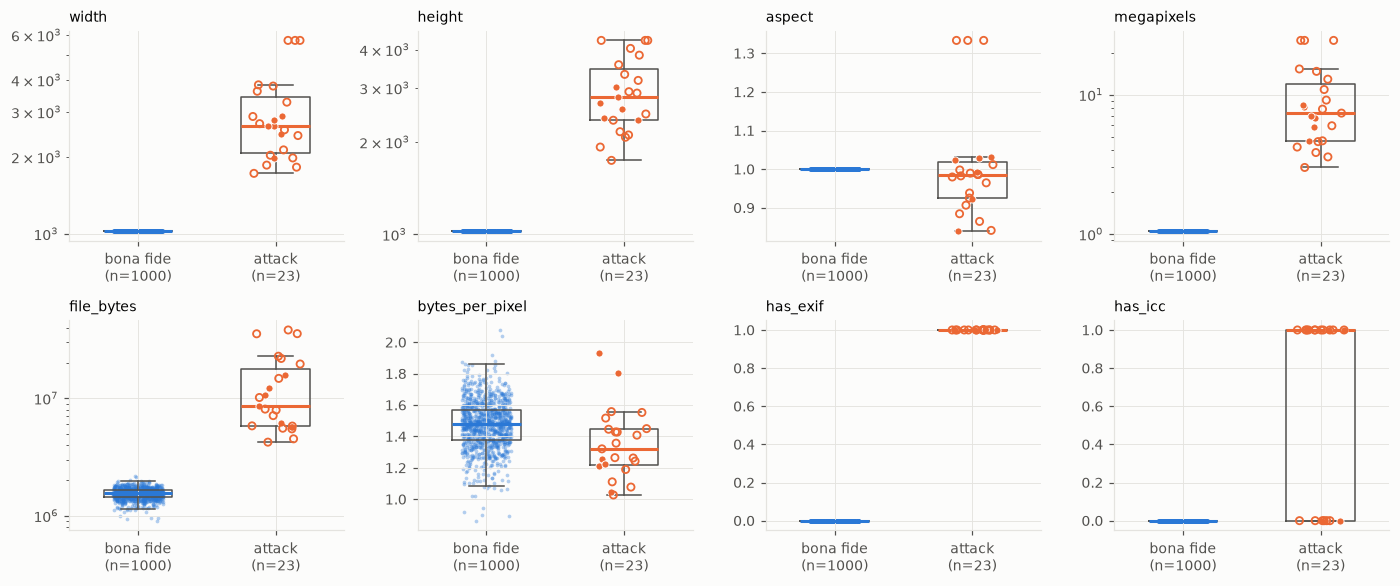

In [5]:
dist_grid(meta, META, log=("width", "height", "megapixels", "file_bytes"));

In [6]:
print("bona fide sizes:", meta.loc[meta.label == 0, ["width", "height"]].drop_duplicates().values.tolist())
print("attack sizes:   ", meta.loc[meta.label == 1, ["width", "height"]].drop_duplicates().shape[0], "distinct")
print("EXIF camera:    ", meta.loc[meta.label == 1, "exif_model"].value_counts().to_dict())
print("ICC profiles:   ", meta.groupby("cls")["has_icc"].mean().round(3).to_dict(), "(fraction with an embedded profile)")

bona fide sizes: [[1024, 1024]]
attack sizes:    21 distinct
EXIF camera:     {'iPhone 15': 14, 'SM-A127F': 9}
ICC profiles:    {'attack': 0.609, 'bona fide': 0.0} (fraction with an embedded profile)


**Reading.** Every bona fide image is exactly 1024x1024 with no EXIF and no colour profile. Every attack is a larger photo (21 distinct sizes, 3-24 MP) from one of two phones (iPhone 15 or Samsung Galaxy A12), all carrying EXIF and 61% carrying an embedded colour profile. Width, height, megapixels, file size and EXIF presence each separate the classes **perfectly** on their own (AUC = 1.0, `overlap = False`). Aspect ratio and bytes-per-pixel overlap. Two capture devices also means the attack set mixes two camera pipelines (sensor, demosaicing, sharpening, colour processing), which is worth remembering when reading per-attack differences.

## 3. Shortcut demonstration: logistic regression on metadata alone

If a classifier given only these meaningless file properties is perfect, then any model that can see them (directly, or through image size / resampling artefacts) is at risk of learning them instead of the screen cue. Cross-validation folds are grouped by image ID so twins never straddle a fold.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def grouped_cv_lr(X, y, groups, n_splits=5):
    cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    oof = np.zeros(len(y))
    for tr, te in cv.split(X, y, groups):
        clf = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=5000))
        oof[te] = clf.fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te])[:, 1]
    full = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=5000)).fit(X, y)
    coefs = pd.Series(full[-1].coef_[0], index=X.columns).sort_values(key=np.abs, ascending=False)
    return oof, coefs


y, groups = meta["label"].to_numpy(), meta["id"].to_numpy()
oof, coefs = grouped_cv_lr(meta[META], y, groups)
cm = confusion_matrix(y, oof >= 0.5)
print(f"out-of-fold AUC {roc_auc_score(y, oof):.3f}")
display(pd.DataFrame(cm, index=["true bona fide", "true attack"], columns=["pred bona fide", "pred attack"]))
display(coefs.rename("standardised coefficient").to_frame())

rule = (meta["width"] != 1024).astype(int)
print("one-line rule 'width != 1024 -> attack':", confusion_matrix(y, rule).ravel().tolist(), "(tn, fp, fn, tp)")

out-of-fold AUC 1.000


,pred bona fide,pred attack
true bona fide,1000,0
true attack,0,23


,standardised coefficient
has_exif,1.143
height,0.653
width,0.542
megapixels,0.392
has_icc,0.378
file_bytes,0.321
aspect,-0.274
bytes_per_pixel,-0.210


one-line rule 'width != 1024 -> attack': [1000, 0, 0, 23] (tn, fp, fn, tp)


**Reading.** The metadata-only classifier is perfect out of fold, and so is a one-line rule on image width. This is the central data-quality finding: the raw files carry a complete shortcut. Everything downstream therefore works on **face crops decoded through one loader** (orientation applied, colour converted to sRGB, metadata dropped, fixed output size), and the inference path applies exactly the same steps.

## 4. Face detection and crop geometry

Faces are detected with YuNet; each crop is a square of side k x the face box (tight k = 1.0, loose k = 1.25) resized to 384 px. Cropping relative to the face makes **framing** identical across classes, but it cannot equalise **source resolution**: `resample_ratio` is how much each crop was shrunk to reach 384 px.

n      mean      std    median       q25       q75      min       max
feature              class                                                                             
face_w               bona fide  999   546.227   34.918   545.233   523.981   569.254  431.912   704.797
                     attack      23  1610.195  713.897  1320.078  1201.398  1937.881  925.590  3409.152
face_frac            bona fide  999     0.533    0.034     0.532     0.512     0.556    0.422     0.688
                     attack      23     0.557    0.089     0.533     0.501     0.581    0.453     0.796
det_score            bona fide  999     0.916    0.012     0.918     0.912     0.923    0.689     0.940
                     attack      23     0.913    0.016     0.917     0.907     0.922    0.863     0.937
roll_deg             bona fide  999     0.059    2.410     0.162    -1.536     1.717   -8.437     7.564
                     attack      23     0.103    2.242    -0.372    -1.270     1.402   -4.205     5.503
n_faces              bona fide  999     1.056    0.281     1.000     1.000     1.000    1.000     5.000
                     attack      23     1.043    0.209     1.000     1.000     1.000    1.000     2.000
tight_resample_ratio bona fide  999     1.905    0.117     1.909     1.826     1.987    1.453     2.297
                     attack      23     5.602    2.391     4.755     4.169     6.435    3.138    11.156
loose_resample_ratio bona fide  999     2.381    0.144     2.385     2.281     2.482    1.815     2.667
                     attack      23     6.674    2.291     5.943     5.156     8.042    3.924    11.156

,auc,cliffs_delta,p_value,overlap
face_w,1.000,1.000,2.244e-16,False
tight_resample_ratio,1.000,1.000,2.240e-16,False
loose_resample_ratio,1.000,1.000,2.240e-16,False
det_score,0.453,-0.093,4.433e-01,True
roll_deg,0.487,-0.027,8.275e-01,True
face_frac,0.495,-0.011,9.305e-01,True
n_faces,0.499,-0.003,9.482e-01,True


no face found: [{'id': '25301', 'cls': 'bona fide', 'split': 'train'}]


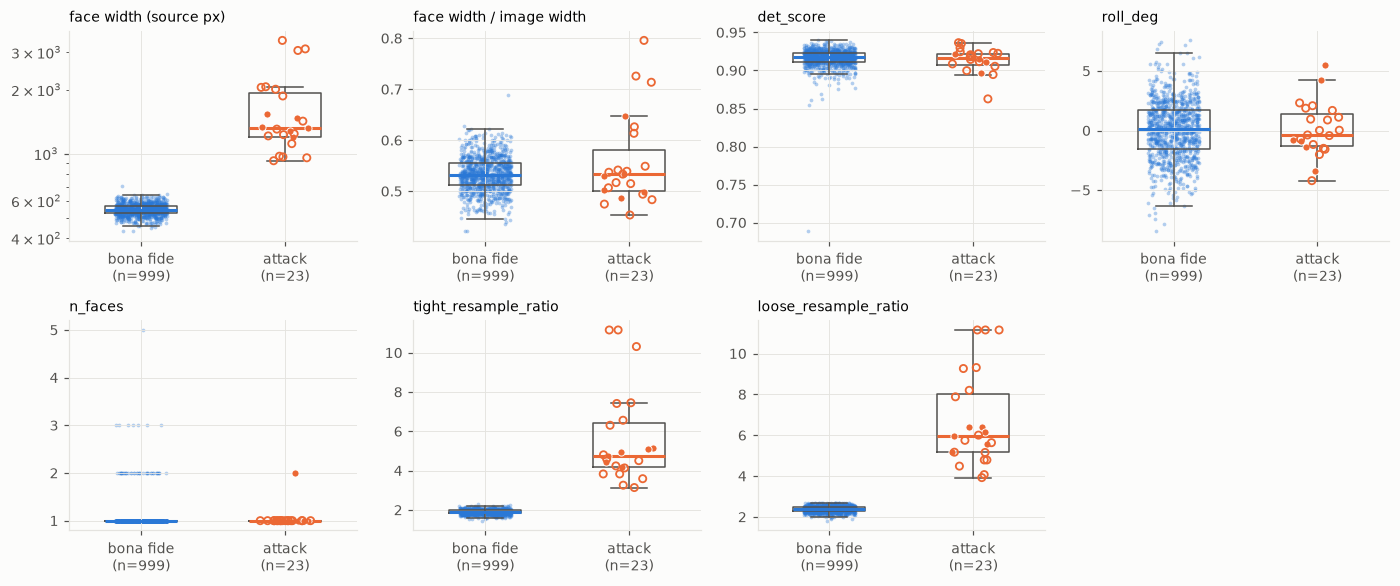

In [8]:
GEOM = ["face_w", "face_frac", "det_score", "roll_deg", "n_faces", "tight_resample_ratio", "loose_resample_ratio"]
geom = df[df["face_found"]].copy()
geom_table, geom_sep = class_summary(geom, GEOM)
display(geom_table)
display(geom_sep)
dist_grid(geom, GEOM, log=("face_w",), titles={"face_w": "face width (source px)", "face_frac": "face width / image width"});
print("no face found:", df.loc[~df["face_found"], ["id", "cls", "split"]].to_dict("records"))

**Reading.** Detection is reliable in both classes (one bona fide failure, which falls back to a centre crop) and head roll is small, so no rotation alignment is needed. Relative face size (`face_frac`) overlaps between classes, so the crops are comparably framed. But faces in attacks are ~3x more pixels wide, so **attack crops are downsampled 3.8-11x versus 1.7-2.7x for bona fide, with no overlap**. That is a second, subtler shortcut: an image's resampling history leaves traces in its fine texture. It is countered by (a) training on synthetic attacks made from the bona fide images, which share the bona fide resampling path, and (b) seeded random down/up-sampling of every training image (`screenpad.data.augment.rescale_jitter`).

## 5. Pixel and spectral statistics on the face crops

Statistics computed on the tight 384 px crops, i.e. on what a model actually sees after preprocessing:

| feature | meaning |
|---|---|
| brightness, contrast | mean and std of CIELAB lightness |
| colour_a, colour_b | mean CIELAB a* (green-red) and b* (blue-yellow): colour cast |
| saturation | mean HSV saturation |
| sharpness | log10 variance of the Laplacian |
| noise_sigma | robust (MAD) std of the high-pass residual (image minus a sigma-1 Gaussian blur) |
| highlight_frac | fraction of very bright, desaturated pixels: glare / specular reflection |
| clipped_frac | fraction of pixels with a channel at 0-2 or 253-255 |
| hf_ratio | fraction of spectral power above 0.25 cycles/pixel |
| peak_score | height of the strongest isolated spectral peak above the median at its radius: periodic structure such as moiré or a pixel grid |

In [9]:
cache = load_cache(Path(cfg.data.cache_dir) / "crops_tight_384.npz")
order = pd.DataFrame({"id": cache["id"], "label": cache["label"]})
px = pd.concat([order, pixel_stats_frame(cache["images"])], axis=1).merge(df[["id", "label", "split", "cls"]], on=["id", "label"])
PIX = ["brightness", "contrast", "colour_a", "colour_b", "saturation", "sharpness", "noise_sigma",
       "highlight_frac", "clipped_frac", "hf_ratio", "peak_score"]
px_table, px_sep = class_summary(px, PIX)
display(px_table)
display(px_sep)

n    mean     std     median        q25        q75        min     max
feature        class                                                                              
brightness     bona fide  1000  49.187  10.593  4.902e+01  4.232e+01  5.611e+01  1.843e+01  81.450
               attack       23  44.581   5.768  4.564e+01  4.090e+01  4.939e+01  3.242e+01  52.312
contrast       bona fide  1000  21.410   4.451  2.129e+01  1.819e+01  2.422e+01  9.624e+00  35.727
               attack       23  22.181   3.678  2.168e+01  2.003e+01  2.345e+01  1.579e+01  31.035
colour_a       bona fide  1000  11.975   4.545  1.172e+01  9.018e+00  1.469e+01 -1.087e+00  36.642
               attack       23  13.178   5.600  1.309e+01  1.014e+01  1.608e+01  4.015e+00  28.693
colour_b       bona fide  1000  13.120   7.020  1.283e+01  8.676e+00  1.701e+01 -2.642e+01  55.203
               attack       23  13.146   7.113  1.444e+01  8.552e+00  1.907e+01 -2.951e+00  22.520
saturation     bona fide  1000   0.383   0.112  3.715e-01  3.031e-01  4.533e-01  1.137e-01   0.894
               attack       23   0.429   0.087  4.393e-01  3.687e-01  4.865e-01  2.632e-01   0.612
sharpness      bona fide  1000   2.316   0.239  2.310e+00  2.152e+00  2.467e+00  1.335e+00   3.168
               attack       23   2.574   0.306  2.660e+00  2.442e+00  2.817e+00  1.900e+00   2.973
noise_sigma    bona fide  1000   1.839   0.514  1.779e+00  1.480e+00  2.111e+00  6.838e-01   4.804
               attack       23   2.885   1.555  2.550e+00  1.865e+00  3.094e+00  1.255e+00   6.532
highlight_frac bona fide  1000   0.010   0.028  2.136e-04  6.782e-06  5.056e-03  0.000e+00   0.283
               attack       23   0.002   0.006  0.000e+00  0.000e+00  6.341e-04  0.000e+00   0.027
clipped_frac   bona fide  1000   0.042   0.077  1.006e-02  6.765e-04  4.843e-02  0.000e+00   0.783
               attack       23   0.012   0.016  4.869e-03  6.002e-04  1.933e-02  0.000e+00   0.063
hf_ratio       bona fide  1000   0.027   0.018  2.243e-02  1.500e-02  3.467e-02  9.048e-04   0.152
               attack       23   0.048   0.052  2.551e-02  1.517e-02  5.835e-02  6.005e-03   0.202
peak_score     bona fide  1000   1.544   0.209  1.504e+00  1.398e+00  1.648e+00  1.203e+00   2.772
               attack       23   2.109   0.983  1.628e+00  1.446e+00  2.416e+00  1.256e+00   4.210

,auc,cliffs_delta,p_value,overlap
sharpness,0.763,0.526,1.584e-05,True
noise_sigma,0.741,0.482,7.591e-05,True
highlight_frac,0.336,-0.328,6.631e-03,True
peak_score,0.650,0.300,1.372e-02,True
saturation,0.643,0.286,1.898e-02,True
brightness,0.362,-0.277,2.302e-02,True
clipped_frac,0.417,-0.165,1.754e-01,True
hf_ratio,0.579,0.158,1.957e-01,True
colour_a,0.562,0.123,3.123e-01,True
contrast,0.554,0.107,3.798e-01,True


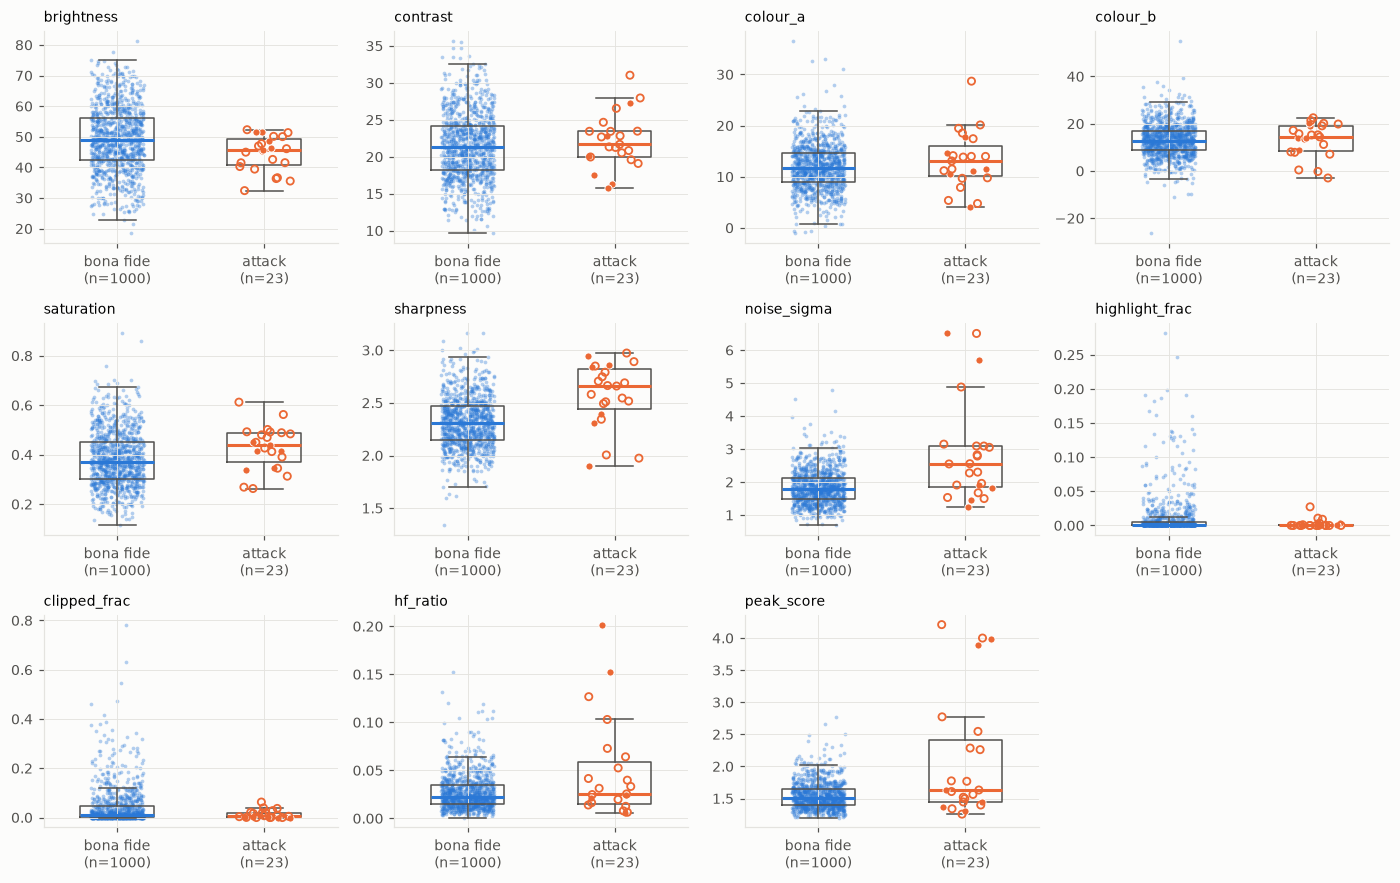

In [10]:
dist_grid(px, PIX, ncols=4);

**Reading.** After cropping, **every feature overlaps between classes**: no single statistic separates them. The strongest population shifts are sharpness (attacks sharper), noise, spectral peaks and fewer glare-like highlights; brightness and saturation also shift (attacks somewhat darker and more saturated, with a narrower spread). Whether a shift is caused by *recapture* or by *which images happened to be attacked* cannot be told from population statistics; the paired analysis in section 6 separates the two. With 23 attacks all of these estimates are noisy.

## 6. Paired analysis: each attack against its own twin

Population comparisons mix the recapture effect with content differences between faces. Each attack has a twin showing the identical face, so the **within-pair difference** isolates what recapture did to the image. A Wilcoxon signed-rank test asks whether the differences are consistently non-zero.

,median diff (attack - twin),attack higher in,wilcoxon p
sharpness,2.158e-01,20 / 23,4.029e-05
noise_sigma,4.631e-01,20 / 23,2.148e-04
hf_ratio,4.464e-03,19 / 23,4.752e-04
peak_score,5.772e-02,15 / 23,3.009e-02
clipped_frac,-7.792e-03,9 / 23,3.838e-02
highlight_frac,-1.356e-05,7 / 23,3.661e-01
colour_b,7.243e-01,13 / 23,5.600e-01
contrast,-2.490e-01,10 / 23,6.650e-01
saturation,3.189e-02,13 / 23,7.090e-01
colour_a,-4.606e-01,9 / 23,8.462e-01


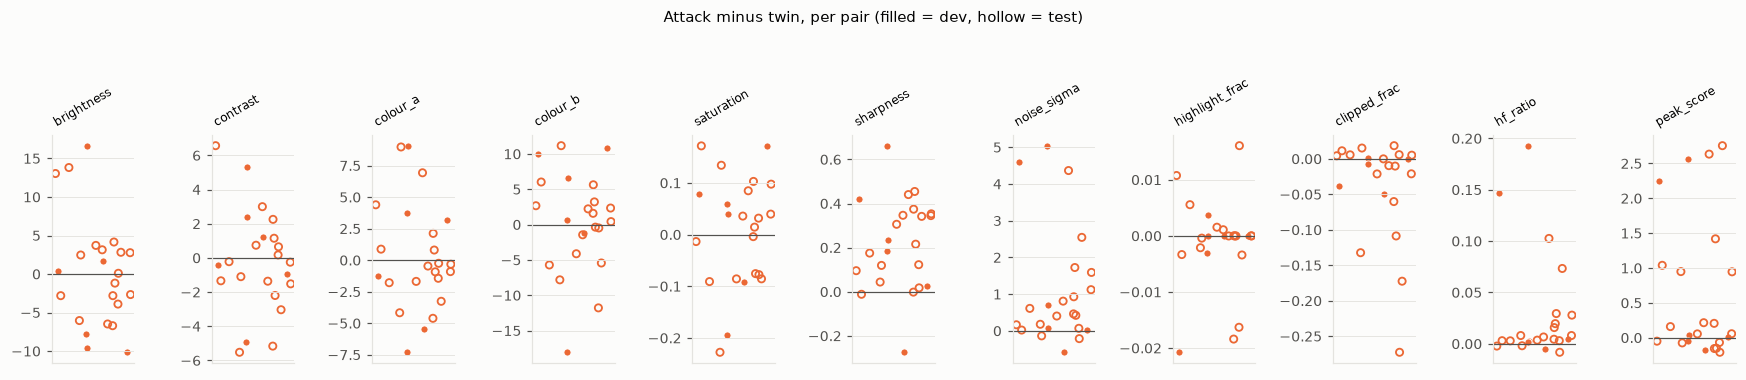

In [11]:
from scipy.stats import wilcoxon

pairs = px[px["id"].isin(px.loc[px.label == 1, "id"])].pivot_table(index="id", columns="label", values=PIX)
diff = pd.DataFrame({c: pairs[(c, 1)] - pairs[(c, 0)] for c in PIX})
split_of = px[px.label == 1].set_index("id")["split"]
paired = pd.DataFrame({
    "median diff (attack - twin)": diff.median(),
    "attack higher in": (diff > 0).sum().astype(str) + " / " + str(len(diff)),
    "wilcoxon p": [wilcoxon(diff[c]).pvalue for c in PIX],
}).sort_values("wilcoxon p")
display(paired)

fig, axes = plt.subplots(1, len(PIX), figsize=(1.45 * len(PIX), 3.2), sharey=False)
for ax, c in zip(axes, PIX):
    d = diff[c]
    dev = split_of.reindex(d.index).eq("dev").to_numpy()
    ax.axhline(0, color=INK_2, lw=0.8)
    xj = np.random.default_rng(SEED).uniform(-0.15, 0.15, len(d))
    ax.scatter(xj[dev], d[dev], s=22, color=ATTACK_C, edgecolor="white", lw=0.6)
    ax.scatter(xj[~dev], d[~dev], s=22, facecolor="none", edgecolor=ATTACK_C, lw=1.2)
    ax.set_xticks([]); ax.set_title(c, fontsize=8, rotation=30, ha="left", loc="left")
fig.suptitle("Attack minus twin, per pair (filled = dev, hollow = test)", fontsize=10, y=1.06)
fig.tight_layout();

**Reading.**
- **Consistent recapture effects:** sharpness and high-pass noise each rise in 20/23 pairs and high-frequency energy in 19/23; spectral peaks rise in most pairs (moiré / pixel-grid structure); clipped pixels fall slightly. These are what the attack simulator has to reproduce.
- **Brightness, saturation and colour do not shift consistently within pairs** (roughly half the pairs each way), so their population-level differences in section 5 come from *which* images were chosen for attack, not from recapture. A model that learned them would be learning a selection artefact.
- **Caution on sharpness / high-frequency energy:** attack crops are downsampled 3-6x harder than their twins (section 4), and downsampling a higher-resolution capture yields a crisper crop. Part of this "recapture" effect may therefore be resampling history rather than the screen. Rescale augmentation and synthetic attacks built from the bona fide images are what keep a model from depending on it.

Direction and spread of these shifts, not just the mean, are the simulator's calibration targets; they are described here on all pairs, but the simulator is calibrated on the 6 dev pairs only.

## 7. What survives cropping: logistic regression on crop statistics

Same grouped-CV logistic regression as section 3, now on the crop statistics instead of metadata. This is not a proposed model; it measures how much class information simple global statistics carry once the file-level shortcut is removed.

out-of-fold AUC on crop statistics: 0.826


,standardised coefficient
clipped_frac,-3.656
saturation,1.389
contrast,0.966
sharpness,0.919
colour_b,-0.480
hf_ratio,-0.477
peak_score,0.432
noise_sigma,0.404
highlight_frac,-0.323
colour_a,-0.273


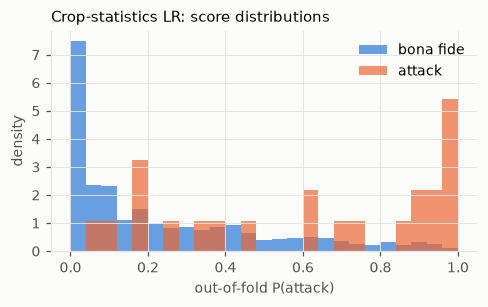

In [12]:
oof_px, coefs_px = grouped_cv_lr(px[PIX], px["label"].to_numpy(), px["id"].to_numpy())
print(f"out-of-fold AUC on crop statistics: {roc_auc_score(px['label'], oof_px):.3f}")
display(coefs_px.rename("standardised coefficient").to_frame())

fig, ax = plt.subplots(figsize=(5, 2.6))
bins = np.linspace(0, 1, 26)
ax.hist(oof_px[px.label == 0], bins=bins, color=BONAFIDE_C, alpha=0.7, density=True, label="bona fide")
ax.hist(oof_px[px.label == 1], bins=bins, color=ATTACK_C, alpha=0.7, density=True, label="attack")
ax.set_xlabel("out-of-fold P(attack)"); ax.set_ylabel("density"); ax.legend(frameon=False)
ax.set_title("Crop-statistics LR: score distributions", loc="left", fontsize=10);

**Reading.** Metadata gave a perfect classifier; global crop statistics give a weaker, overlapping one (out-of-fold AUC printed above). That drop is the file-level shortcut being removed. Note which coefficients carry it: clipping and saturation, which section 6 showed are **not** consistent recapture effects, rank alongside sharpness. So even this simple model leans partly on selection artefacts, which is a concrete warning for the learned models: their attention has to be checked (phase 5), not assumed. This linear model on 11 global statistics is the floor later models have to beat on dev.

## 8. Summary

1. **File metadata is a complete shortcut** (section 3): perfect separation from size, file size or EXIF alone. All modelling uses face crops through a single loader that strips metadata and fixes the output size.
2. **Resampling history is a second, subtler shortcut** (section 4): attack crops are downsampled 3.8-11x, bona fide 1.7-2.7x, with no overlap. Countered by synthetic attacks built from bona fide images and by seeded random down/up-sampling in training.
3. **After cropping, every feature overlaps between classes** (section 5); none separates them alone.
4. **Pairs separate cause from selection** (section 6): sharpness, noise, high-frequency energy and spectral peaks rise consistently with recapture; brightness, saturation and colour differences are selection artefacts. Part of the sharpness and noise rise may itself be resampling history or phone-camera processing (sharpening, sensor noise). The consistent paired shifts are the simulator's calibration targets (dev pairs only).
5. **Global statistics give a partial, partly confounded classifier** (section 7): even a linear model leans on selection artefacts, so learned models need explainability checks, and detection has to come from local texture and frequency structure.
6. **Two capture phones** (iPhone 15, Samsung Galaxy A12): the test attacks cover only these two camera pipelines and one or two displays, so results will say little about other devices.